# 13 – Phase 3b: what makes Fatemeh's V4 better? (leave-one-out ablation)

**Starting point.**
- Fatemeh's **V4** is the team's best model: OOF 0.859 clean / 0.851 shifted, Kaggle **0.8678**.
- My **E3** reaches 0.847 / 0.846, Kaggle 0.8574.

Same backbone, data and folds, but V4 changes **many things at once** compared with E3, so we do not know which ones matter.

**Method: leave-one-out ablation.**
1. Rebuild V4 inside `train_lib.py` (`T.v4_config()`, run `v4_repro`) and check that it reproduces her scores (≈ 0.859 / 0.851, within ~0.01).
2. Re-train it **six times, each time removing one component**. If the score drops when a component is removed, that component helps; if the score stays the same or rises, it is useless or harmful.

| run | V4 minus … | what it tests |
|---|---|---|
| **R0** `v4_repro` | nothing | the pipeline reproduces V4 |
| **A1** `v4_no_geo` | free rotation, zoom, shift (back to the 8 symmetries only) | does continuous geometry help? |
| **A2** `v4_no_cw` | class weights | hypothesis: they explain V4's lead on **disturbed** and **cigar** |
| **A3** `v4_e3_colour` | saturation, channel gains, brightness/contrast, channel shuffle (hue rotation kept) | is the strong colour augmentation needed, or is hue enough? |
| **A4** `v4_mild_blur` | strong blur (p 0.5, σ 0.3–2.0) → E3's mild blur (p 0.25, σ 0.1–1.2) | hypothesis: strong blur hurts **tight spiral** |
| **A5** `v4_no_artifacts` | synthetic lines and rectangles | are the artifacts useful? |
| **A6** `v4_20ep_b64` | 25 epochs, batch 32 → 20 epochs, batch 64 (E3's schedule) | is the longer training (≈ 2.5× more updates) needed? |

Noise (p 0.25) is not ablated separately: in phase 3 it had no measurable effect (E4 ≈ E3).

**Decision rule.** The lesson of notebook 12 applies here: among models that are all trained with colour/blur augmentation, Kaggle followed the **clean** validation, while the shifted one slightly favours E3-style augmentation. So we look at **both** validations, fold by fold, against R0:
- **useful:** removing it lowers clean or shifted by ≳ 0.005, on ≥ 4/5 folds → keep;
- **harmful:** removing it raises the clean F1 by ≳ 0.005 (≥ 4/5 folds) without lowering the shifted → drop;
- **neutral:** everything else → can be dropped for simplicity, but this is decided together with the others.

A single training run has a seed noise of a few thousandths, so differences below ~0.005 are not interpreted.

**Time:** ≈ 15–20 min per run (batch 32 and 25 epochs are slower than E3) → **≈ 2–2.5 h** in total. Run it inside `tmux`:
```
tmux new -s phase3b
cd ~/ANN-DL-Challenge/families/elia && source ../../.venv/bin/activate
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 13_phase3b_v4_ablation.ipynb
```
Detach with `Ctrl+B` then `D`, and reattach with `tmux attach -t phase3b`. Completed runs are skipped if the notebook is restarted.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, random
from sklearn.metrics import f1_score

import train_lib as T
import common as C

plt.rcParams["figure.dpi"] = 80
SMOKE_TEST = False          # True = tiny run (few images, 1 epoch, fold 0) only to check that the code works
data = T.load_data(smoke_test=SMOKE_TEST)
print("device:", T.DEVICE, "| outputs:", T.OUT_DIR)

loaded 2995 training images (+ shifted versions) in 7s
device: cuda | outputs: /home/elia/ANN-DL-Challenge/families/elia/outputs


## 1. What the V4 augmentations look like

Eight training images, with each **group** of V4 augmentations applied alone, and then the full V4 pipeline. In training each step is applied with its own probability:

| step | probability |
|---|---|
| geometry | 100% |
| hue | 50% |
| saturation | 100% |
| channel gains | 50% |
| brightness/contrast | 100% |
| channel shuffle | 20% |
| blur | 50% |
| noise | 25% |
| lines | 30% |
| rectangles | 30% |

**Check:**
- the galaxies must stay recognisable;
- the **zoom-out + shift** uses reflected borders, so a mirrored copy of part of the galaxy can appear at the edge. This is the same in Fatemeh's notebook.

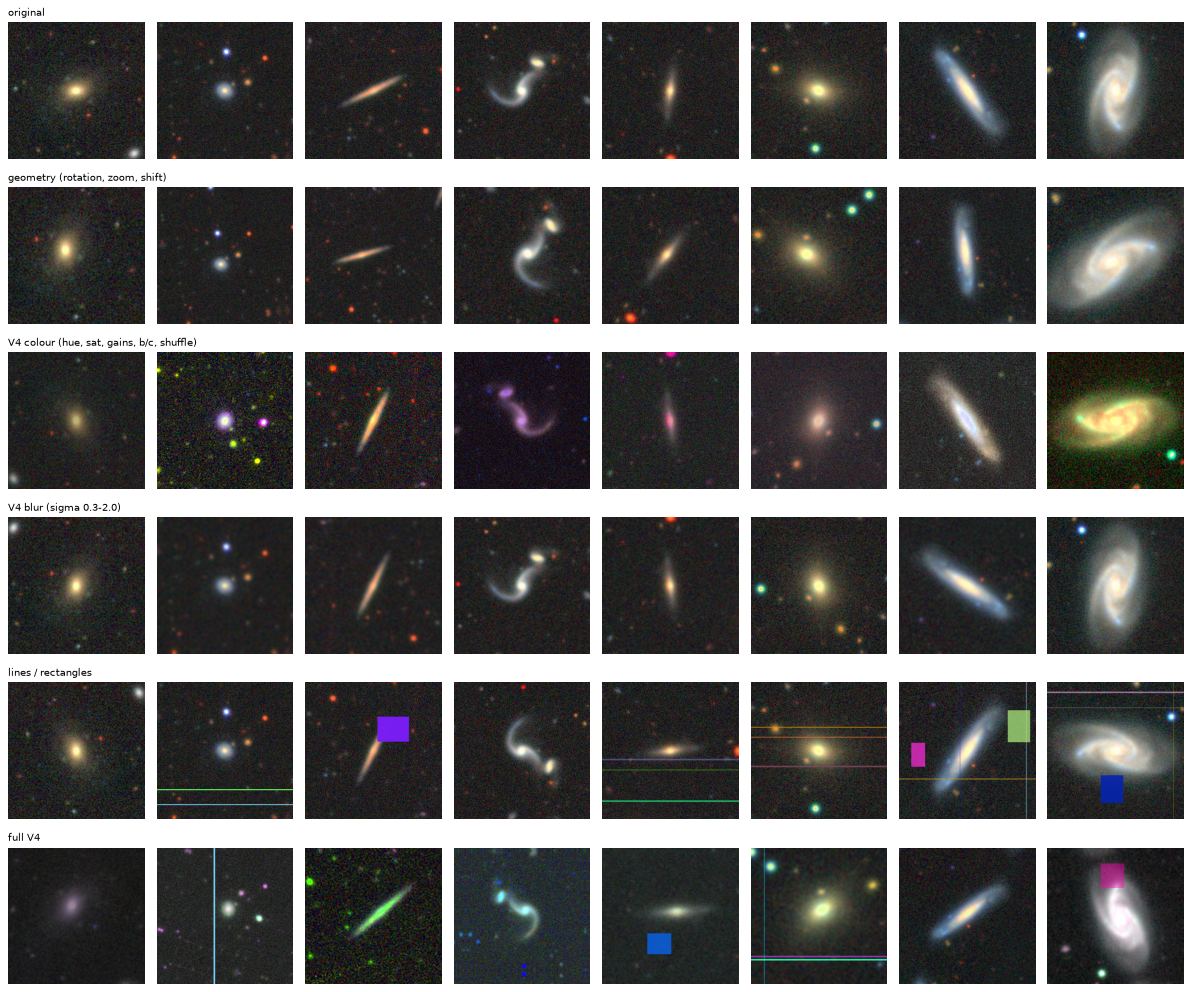

In [2]:
x0 = T.to_float(data["X_clean"][:8], 256)
v4 = T.v4_config()
off = dict(geo_p=0, hue_p=0, sat_p=0, gain_p=0, bc_p=0, shuffle_p=0, blur_p=0, noise_p=0, lines_p=0, patch_p=0)
variants = {
    "original": None,
    "geometry (rotation, zoom, shift)": {**v4, **off, "geo_p": 1.0},
    "V4 colour (hue, sat, gains, b/c, shuffle)": {**v4, **off, "hue_p": 0.5, "sat_p": 1.0, "gain_p": 0.5, "bc_p": 1.0, "shuffle_p": 0.2},
    "V4 blur (sigma 0.3-2.0)": {**v4, **off, "blur_p": 1.0},
    "lines / rectangles": {**v4, **off, "lines_p": 0.5, "patch_p": 0.5},
    "full V4": v4,
}
torch.manual_seed(0); random.seed(0)
fig, axes = plt.subplots(len(variants), 8, figsize=(15, 2.1 * len(variants)))
for r, (name, cfg) in enumerate(variants.items()):
    xs = x0.clone() if cfg is None else T.augment(T.random_dihedral(x0.clone()), cfg)
    xs = xs.permute(0, 2, 3, 1).cpu().numpy()
    for c in range(8):
        axes[r, c].imshow(xs[c]); axes[r, c].axis("off")
    axes[r, 0].set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 2. The experiments

In [3]:
EXPERIMENTS = [
    T.v4_config(),                                                                    # R0
    T.v4_config(run_name="v4_no_geo", note="V4 - free rotation/zoom/shift", geo_p=0.0),
    T.v4_config(run_name="v4_no_cw", note="V4 - class weights", class_weight_power=0.0),
    T.v4_config(run_name="v4_e3_colour", note="V4 - sat/gains/brightness-contrast/shuffle (hue kept)",
                sat_p=0.0, gain_p=0.0, bc_p=0.0, shuffle_p=0.0),
    T.v4_config(run_name="v4_mild_blur", note="V4 with E3 blur (p .25, sigma 0.1-1.2)",
                blur_p=0.25, blur_sigma=(0.1, 1.2)),
    T.v4_config(run_name="v4_no_artifacts", note="V4 - lines/rectangles", lines_p=0.0, patch_p=0.0),
    T.v4_config(run_name="v4_20ep_b64", note="V4 with 20 epochs, batch 64", epochs=20, batch_size=64),
]
if SMOKE_TEST:
    for cfg in EXPERIMENTS:
        cfg.update(run_name=cfg["run_name"] + "_SMOKE", epochs=1, folds=[0], batch_size=16)

KEYS = ["run_name", "geo_p", "hue_p", "sat_p", "gain_p", "bc_p", "shuffle_p", "blur_p", "blur_sigma",
        "noise_p", "lines_p", "patch_p", "class_weight_power", "epochs", "batch_size"]
pd.DataFrame(EXPERIMENTS)[KEYS]

,run_name,geo_p,hue_p,sat_p,gain_p,bc_p,shuffle_p,blur_p,blur_sigma,noise_p,lines_p,patch_p,class_weight_power,epochs,batch_size
0,v4_repro,1.0,0.5,1.0,0.5,1.0,0.2,0.50,"(0.3, 2.0)",0.25,0.3,0.3,0.5,25,32
1,v4_no_geo,0.0,0.5,1.0,0.5,1.0,0.2,0.50,"(0.3, 2.0)",0.25,0.3,0.3,0.5,25,32
2,v4_no_cw,1.0,0.5,1.0,0.5,1.0,0.2,0.50,"(0.3, 2.0)",0.25,0.3,0.3,0.0,25,32
3,v4_e3_colour,1.0,0.5,0.0,0.0,0.0,0.0,0.50,"(0.3, 2.0)",0.25,0.3,0.3,0.5,25,32
4,v4_mild_blur,1.0,0.5,1.0,0.5,1.0,0.2,0.25,"(0.1, 1.2)",0.25,0.3,0.3,0.5,25,32
5,v4_no_artifacts,1.0,0.5,1.0,0.5,1.0,0.2,0.50,"(0.3, 2.0)",0.25,0.0,0.0,0.5,25,32
6,v4_20ep_b64,1.0,0.5,1.0,0.5,1.0,0.2,0.50,"(0.3, 2.0)",0.25,0.3,0.3,0.5,20,64


In [4]:
results = {}
for cfg in EXPERIMENTS:
    results[cfg["run_name"]] = T.run_experiment(cfg, data)

loaded 14736 test images in 15s


v4_repro | fold 0 | epoch  1 | train loss 2.109 | F1 clean 0.523 | F1 shifted 0.515 | 28s


v4_repro | fold 0 | epoch  2 | train loss 1.613 | F1 clean 0.688 | F1 shifted 0.675 | 9s


v4_repro | fold 0 | epoch  3 | train loss 1.369 | F1 clean 0.708 | F1 shifted 0.708 | 9s


v4_repro | fold 0 | epoch  4 | train loss 1.284 | F1 clean 0.737 | F1 shifted 0.741 | 9s


v4_repro | fold 0 | epoch  5 | train loss 1.224 | F1 clean 0.781 | F1 shifted 0.771 | 9s


... (876 outputs left out)

v4_20ep_b64 | fold 4 | epoch 18 | train loss 0.944 | F1 clean 0.831 | F1 shifted 0.829 | 5s


v4_20ep_b64 | fold 4 | epoch 19 | train loss 0.931 | F1 clean 0.834 | F1 shifted 0.835 | 5s


v4_20ep_b64 | fold 4 | epoch 20 | train loss 0.914 | F1 clean 0.834 | F1 shifted 0.837 | 5s



v4_20ep_b64 | fold 4 with TTA: F1 clean 0.8390 | F1 shifted 0.8356 | 2.6 min

v4_20ep_b64 done in 13.3 min: OOF F1 clean 0.8461 | shifted 0.8422


## 3. Does R0 reproduce Fatemeh's V4?

`v4_fatemeh` is her Kaggle run, saved in our format by notebook 12; it must be in `outputs/v4_fatemeh/oof.csv`. If `v4_repro` is within ~0.01 of it on both validations, the rebuild is faithful and the ablations below are about V4.

The rebuild is not identical:
- hue is rotated in HSV (hers in YIQ);
- training uses bf16 (hers fp16);
- the random seeds are different.

So a small difference is expected.

In [5]:
RUNS = [cfg["run_name"] for cfg in EXPERIMENTS]
R0 = RUNS[0]
T.compare(["v4_fatemeh", "e3_hue_blur"], reference=R0).style.format("{:.4f}")

,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
v4_repro,0.8498,0.8455,0.0000,0.0000,0.0043,0.8333,0.8403
v4_fatemeh,0.8587,0.8513,0.0089,0.0058,0.0074,0.8361,0.8197
e3_hue_blur,0.8467,0.8458,-0.0032,0.0003,0.0009,0.7863,0.7899


## 4. Leave-one-out: what happens when each component is removed

Out-of-fold weighted F1 of every ablation, with the difference from R0 (`Δ`). A **negative Δ** means that removing the component makes things worse, i.e. **the component helps**.

In [6]:
table = T.compare(RUNS[1:], reference=R0)
table.style.format("{:.4f}").background_gradient(subset=["Δ clean", "Δ shifted"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
v4_repro,0.8498,0.8455,0.0000,0.0000,0.0043,0.8333,0.8403
v4_no_geo,0.8463,0.8442,-0.0035,-0.0013,0.0021,0.8065,0.7937
v4_no_cw,0.8528,0.8464,0.0029,0.0009,0.0064,0.8793,0.8596
v4_e3_colour,0.8476,0.8427,-0.0022,-0.0028,0.0049,0.8254,0.8189
v4_mild_blur,0.8485,0.8477,-0.0013,0.0021,0.0009,0.8387,0.8320
v4_no_artifacts,0.8513,0.8488,0.0015,0.0033,0.0026,0.8293,0.8095
v4_20ep_b64,0.8461,0.8422,-0.0037,-0.0034,0.0039,0.8254,0.8189


In [7]:
# the same comparison fold by fold (paired: same validation images), Δ = ablation − R0
def fold_f1(run):
    oof = pd.read_csv(T.OUT_DIR / run / "oof.csv")
    out = {}
    for val in ["clean", "shifted"]:
        P = oof[[f"p{c}_{val}" for c in range(C.N_CLASSES)]].to_numpy()
        out[val] = [f1_score(oof.label[oof.fold == k], P[oof.fold == k].argmax(1), average="weighted") for k in range(5)]
    return out

ref = fold_f1(R0)
rows = []
for run in RUNS[1:]:
    if not (T.OUT_DIR / run / "oof.csv").exists():
        continue
    f = fold_f1(run)
    for val in ["clean", "shifted"]:
        d = np.array(f[val]) - np.array(ref[val])
        rows.append({"run": run, "validation": val, **{f"fold {k}": d[k] for k in range(5)},
                     "mean Δ": d.mean(), "folds better than R0": int((d > 0).sum()), "folds worse than R0": int((d < 0).sum())})
paired = pd.DataFrame(rows).set_index(["run", "validation"])
paired.style.format({**{f"fold {k}": "{:+.4f}" for k in range(5)}, "mean Δ": "{:+.4f}"}) \
      .background_gradient(subset=["mean Δ"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

## 5. Per class: testing the two hypotheses

- **Class weights (A2):** if they explain V4's lead on disturbed and cigar, then in `v4_no_cw` **disturbed (0)** and **cigar (4)** should drop compared with R0.
- **Strong blur (A4):** if it hurts the fine spiral arms, then in `v4_mild_blur` **tight spiral (6)** should rise compared with R0.

In [8]:
names = [R0] + RUNS[1:]
pc_clean, pc_shift = T.per_class(names, "clean"), T.per_class(names, "shifted")
delta = lambda t: t.sub(t[R0], axis=0).drop(columns=R0)
print("CLEAN validation: per-class F1 of R0, then Δ of each ablation (negative = the component helps that class)")
display(pd.concat([pc_clean[[R0]], delta(pc_clean)], axis=1).style.format("{:+.3f}").format("{:.3f}", subset=[R0])
        .background_gradient(subset=list(delta(pc_clean).columns), cmap="RdYlGn", vmin=-0.08, vmax=0.08))
print("SHIFTED validation")
display(pd.concat([pc_shift[[R0]], delta(pc_shift)], axis=1).style.format("{:+.3f}").format("{:.3f}", subset=[R0])
        .background_gradient(subset=list(delta(pc_shift).columns), cmap="RdYlGn", vmin=-0.08, vmax=0.08))

CLEAN validation: per-class F1 of R0, then Δ of each ablation (negative = the component helps that class)


,v4_repro,v4_no_geo,v4_no_cw,v4_e3_colour,v4_mild_blur,v4_no_artifacts,v4_20ep_b64
0 disturbed,0.494,+0.001,-0.019,+0.016,+0.015,+0.020,-0.000
1 merging,0.915,-0.016,-0.003,-0.010,-0.008,-0.018,-0.013
2 round smooth,0.928,-0.001,-0.004,-0.004,-0.005,-0.001,+0.000
3 in-between smooth,0.928,-0.004,-0.002,+0.000,-0.003,-0.002,+0.001
4 cigar,0.833,-0.027,+0.046,-0.008,+0.005,-0.004,-0.008
5 barred spiral,0.866,-0.013,+0.006,-0.011,+0.000,-0.004,-0.015
6 tight spiral,0.779,+0.007,+0.001,+0.004,+0.005,+0.010,+0.007
7 loose spiral,0.735,+0.009,+0.020,-0.002,-0.004,+0.016,-0.008
8 edge-on no bulge,0.934,-0.010,+0.002,-0.007,-0.000,-0.002,-0.002
9 edge-on bulge,0.946,-0.005,+0.005,+0.003,-0.003,-0.001,-0.000


SHIFTED validation


,v4_repro,v4_no_geo,v4_no_cw,v4_e3_colour,v4_mild_blur,v4_no_artifacts,v4_20ep_b64
0 disturbed,0.478,+0.003,-0.030,-0.007,+0.019,+0.022,+0.008
1 merging,0.905,-0.011,-0.005,-0.007,-0.000,-0.014,-0.006
2 round smooth,0.927,+0.000,-0.006,+0.000,-0.004,+0.002,+0.000
3 in-between smooth,0.922,-0.000,+0.000,+0.002,-0.003,+0.005,+0.002
4 cigar,0.840,-0.047,+0.019,-0.021,-0.008,-0.031,-0.021
5 barred spiral,0.859,+0.003,-0.000,-0.007,+0.010,+0.002,-0.016
6 tight spiral,0.781,+0.001,+0.007,-0.005,+0.009,+0.013,+0.007
7 loose spiral,0.734,+0.008,+0.013,-0.002,+0.001,+0.012,-0.012
8 edge-on no bulge,0.928,-0.005,+0.008,+0.001,+0.003,-0.000,-0.002
9 edge-on bulge,0.943,-0.007,+0.004,+0.000,-0.003,-0.002,-0.001


## 6. Training curves

Mean over the folds, without TTA. Different schedules (25 vs 20 epochs) are drawn on their own epoch axis.

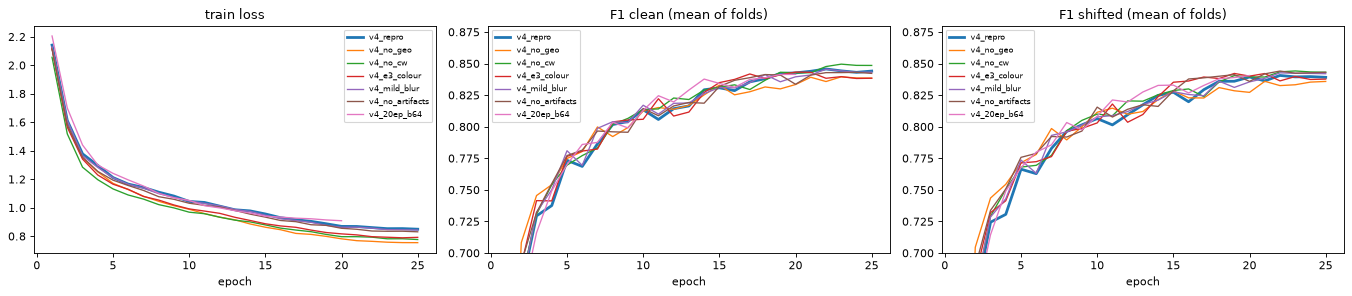

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for name in RUNS:
    f = T.OUT_DIR / name / "history.csv"
    if not f.exists():
        continue
    h = pd.read_csv(f).groupby("epoch").mean(numeric_only=True)
    lw = 2.5 if name == R0 else 1.2
    axes[0].plot(h.index, h.train_loss, label=name, lw=lw)
    axes[1].plot(h.index, h.f1_clean, label=name, lw=lw)
    axes[2].plot(h.index, h.f1_shifted, label=name, lw=lw)
for ax, t in zip(axes, ["train loss", "F1 clean (mean of folds)", "F1 shifted (mean of folds)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
axes[1].set_ylim(0.7, 0.88); axes[2].set_ylim(0.7, 0.88)
plt.tight_layout(); plt.show()

## 7. Decision

Fill in from sections 3–5, applying the rule from the introduction (both validations, fold by fold):

| component | removing it: Δ clean / Δ shifted | folds (worse / better) | verdict |
|---|---|---|---|
| geometry (A1) | ___ / ___ | ___ | ___ |
| class weights (A2) | ___ / ___ | ___ | ___ |
| strong colour (A3) | ___ / ___ | ___ | ___ |
| strong blur (A4) | ___ / ___ | ___ | ___ |
| artifacts (A5) | ___ / ___ | ___ | ___ |
| 25 ep / batch 32 (A6) | ___ / ___ | ___ | ___ |

- R0 reproduces V4? ___
- Hypothesis "class weights → disturbed/cigar": ___
- Hypothesis "strong blur hurts tight spiral": ___

**Next:** a single configuration = V4 without the harmful components (and possibly without the neutral ones). It becomes the reference for phase 4 (resolution, backbone, epochs).